# 04b — DeepLog: Next-Event Prediction & Top-k Anomaly Detection
## สถาปัตยกรรม DeepLog ดั้งเดิม (Du et al., ACM CCS 2017)

**เป้าหมาย:** สร้างโมเดลตรวจจับความผิดปกติของ Log ด้วยแนวทาง **DeepLog** ที่แท้จริง (เรียนรู้ลำดับเหตุการณ์แบบ Next-Event Prediction ด้วย Log ปกติเท่านั้น)

---

### 🧠 ความแตกต่างระหว่างสองแนวทางใน Week 4:

| คุณลักษณะ | 04 Supervised Session LSTM (เพื่อนทำไว้) | 04b DeepLog (Next-Event Prediction) |
|---|---|---|
| **แนวคิดหลัก** | มอง Session ทั้งก้อนแล้วฟันธง `0` หรือ `1` | เลียนแบบการพิมพ์คำทำนายของคีย์บอร์ด (Next-token Prediction) |
| **ข้อมูลที่ใช้ฝึก** | ต้องมีทั้ง Normal และ Anomaly (Supervised) | **ใช้เฉพาะ Log ปกติ (Normal Only) 100%** |
| **โจทย์การเรียนรู้** | Binary Classification (Target: Label) | Multi-class Classification (Target: Event ถัดไป) |
| **การตรวจจับ** | ดูค่า Anomaly Probability $\ge$ Threshold | ตรวจสอบว่า Event จริงอยู่ใน **Top-$k$ Candidates** หรือไม่ |
| **ข้อดีในงาน SOC** | แยกแยะได้แม่นยำบนข้อมูลที่มีเฉลย | **ไม่ต้องง้อข้อมูลการโจมตีตอนเทรน** (ตรงกับสถานการณ์จริงที่การโจมตีหายากมาก) |

---

### 📱 Analogy เข้าใจง่าย: คีย์บอร์ดมือถือเดาคำถัดไป
- เวลาเราพิมพ์: `"กำลังจะออกไปกิน..."` คีย์บอร์ดจะเสนอ 3 คำขึ้นมาด้านบน: `[ข้าว, ก๋วยเตี๋ยว, ชาบู]` (นี่คือ **Top-$k$ Candidates**, $k=3$)
- ถ้าคำถัดไปคือ `"ข้าว"` $\rightarrow$ อยู่ใน 3 ช้อยส์ที่ระบบคาดเดา $\rightarrow$ **พฤติกรรมปกติ 🟢**
- แต่ถ้าจู่ๆ บรรทัดถัดไปโผล่คำว่า `"Ransomware.exe"` หรือข้ามขั้นตอนสำคัญ $\rightarrow$ หลุดจาก Top-$k$ $\rightarrow$ แจ้งเตือนทันทีว่า **"Anomaly! 🔴"**


## Step 1: Import Libraries และกำหนดค่า Hyperparameters

### หลักการ:
- กำหนด Random Seed คงที่ (`42`) เพื่อให้การทดลองทำซ้ำได้ (Reproducibility)
- ตั้งค่าความยาวประวัติ $h$ (`WINDOW_SIZE = 10`) ตามคำแนะนำในงานวิจัย DeepLog
- ตรวจสอบอุปกรณ์ประมวลผล (CUDA / CPU)


In [1]:
from pathlib import Path
import json
import random
import time
from typing import Dict, Iterable, List, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score
)
from torch.utils.data import DataLoader, Dataset

# 1. ตั้งค่า Reproducibility (Random Seed)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device สำหรับประมวลผล: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

# 2. ไฮเปอร์พารามิเตอร์ตามมาตรฐาน DeepLog
WINDOW_SIZE = 10       # ประวัติย้อนหลัง h เหตุการณ์
EMBEDDING_DIM = 32     # ขนาดเวกเตอร์ Representation ของแต่ละ Event
HIDDEN_DIM = 64        # ขนาด Hidden State ของ LSTM
NUM_LAYERS = 2         # จำนวนชั้น LSTM
DROPOUT = 0.2          # ป้องกัน Overfitting
LEARNING_RATE = 0.001  # อัตราการเรียนรู้ของ Adam
BATCH_SIZE = 512       # ขนาด Batch สำหรับฝึก Window
NUM_EPOCHS = 5         # รอบการฝึกสอน (Next-Event ลู่เข้าเร็วมาก)
PAD_ID = 0             # Token พิเศษสำหรับการเติม Padding
UNK_ID = 1             # Token พิเศษสำหรับ Event ที่ไม่เคยเห็น

# ในเปเปอร์ DeepLog การใช้เพียง ~10,000 - 20,000 session ปกติก็ครอบคลุมรูปแบบทั้งหมดของ HDFS แล้ว
# หากต้องการเทรนเต็ม 390,755 session ให้ตั้ง MAX_TRAIN_SESSIONS = None
MAX_TRAIN_SESSIONS = 25000 if not torch.cuda.is_available() else None

# กำหนด Path ของข้อมูลและผลลัพธ์
DATA_DIR = Path('../data/processed/HDFS')
CHECKPOINT_DIR = Path('../checkpoints')
FIGURE_DIR = Path('../results/figures')
METRIC_DIR = Path('../results/metrics')

for directory in [CHECKPOINT_DIR, FIGURE_DIR, METRIC_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("กำหนดค่าเริ่มต้นและ Path เรียบร้อย ✅")


Device สำหรับประมวลผล: cpu
กำหนดค่าเริ่มต้นและ Path เรียบร้อย ✅


## Step 2: โหลดข้อมูล และคัดเลือกเฉพาะ "Normal Sessions" สำหรับ Train

### หลักการสำคัญ (จุดต่างที่สุดจาก 04 เดิม):
- ใน DeepLog เราต้องการสอน AI ให้รู้ว่า **"พฤติกรรมปกติของระบบ HDFS หน้าตาเป็นอย่างไร"**
- ดังนั้น ใน Train Set เราจะ **กรองเอาเฉพาะ `Label == 0` (Normal) เท่านั้น!** 
- เราจะ **ทิ้ง Anomaly ออกจาก Train Set ทั้งหมด** เพื่อพิสูจน์ว่าโมเดลตรวจจับการโจมตีได้โดยไม่ต้องเคยเห็นการโจมตีมาก่อนตอนเทรน


In [2]:
def load_and_verify(path: Path) -> pd.DataFrame:
    """โหลดไฟล์ CSV และตรวจสอบความถูกต้องเบื้องต้น"""
    if not path.is_file():
        raise FileNotFoundError(f"ไม่พบไฟล์: {path}")
    return pd.read_csv(path)

train_raw = load_and_verify(DATA_DIR / 'train.csv')
val_df = load_and_verify(DATA_DIR / 'val.csv')
test_df = load_and_verify(DATA_DIR / 'test.csv')

# กรองเฉพาะ Session ปกติ (Normal = 0) สำหรับการเทรน DeepLog
normal_train = train_raw[train_raw['Label'] == 0].reset_index(drop=True)

if MAX_TRAIN_SESSIONS is not None and len(normal_train) > MAX_TRAIN_SESSIONS:
    train_for_model = normal_train.sample(n=MAX_TRAIN_SESSIONS, random_state=SEED).reset_index(drop=True)
    print(f"สุ่มตัวอย่าง Normal Train มา: {len(train_for_model):,} sessions (จากทั้งหมด {len(normal_train):,})")
else:
    train_for_model = normal_train
    print(f"ใช้ Normal Train ทั้งหมด: {len(train_for_model):,} sessions")

print(f"Validation Set: {len(val_df):,} sessions | Anomaly = {int((val_df.Label == 1).sum()):,}")
print(f"Test Set:       {len(test_df):,} sessions | Anomaly = {int((test_df.Label == 1).sum()):,}")


สุ่มตัวอย่าง Normal Train มา: 25,000 sessions (จากทั้งหมด 390,755)
Validation Set: 86,259 sessions | Anomaly = 2,525
Test Set:       86,260 sessions | Anomaly = 2,526


## Step 3: สร้าง Vocabulary และฟังก์ชัน Encode ลำดับเหตุการณ์

### หลักการ:
- แปลงข้อความสัญลักษณ์ของ Event (เช่น `E1`, `E5`, `E22`) ให้กลายเป็นตัวเลข Index (Integer Token ID)
- สงวน Token พิเศษ:
  - `<PAD>` = `0` (ใช้เติมให้ครบขนาดหน้าต่าง window)
  - `<UNK>` = `1` (กรณีเจอ Event ที่ไม่เคยเห็น)
  - เหตุการณ์จริงจะเริ่มนับตั้งแต่ Index `2` เป็นต้นไป


In [3]:
def build_event_vocab(dataframes: Iterable[pd.DataFrame]) -> Tuple[Dict[str, int], Dict[int, str]]:
    """สร้างพจนานุกรม Event ID จากข้อมูล Sequence ทั้งหมด"""
    unique_events = sorted({
        event for df in dataframes
        for seq in df['Sequence']
        for event in str(seq).split()
        if event
    })
    
    event_to_id = {'<PAD>': PAD_ID, '<UNK>': UNK_ID}
    for idx, event in enumerate(unique_events, start=2):
        event_to_id[event] = idx
        
    id_to_event = {idx: event for event, idx in event_to_id.items()}
    return event_to_id, id_to_event

def encode_sequence(seq_str: str, event_to_id: Dict[str, int]) -> List[int]:
    """แปลง String Sequence เป็น List ของ Integer Token IDs"""
    return [event_to_id.get(event, UNK_ID) for event in str(seq_str).split() if event]

event_to_id, id_to_event = build_event_vocab([train_raw, val_df, test_df])
VOCAB_SIZE = len(event_to_id)

print(f"ขนาด Vocabulary ทั้งหมด: {VOCAB_SIZE} tokens")
print(f"ตัวอย่าง Token ในระบบ: {[f'{k}:{v}' for k, v in list(event_to_id.items())[:8]]} ...")


ขนาด Vocabulary ทั้งหมด: 47 tokens
ตัวอย่าง Token ในระบบ: ['<PAD>:0', '<UNK>:1', 'E1:2', 'E10:3', 'E11:4', 'E12:5', 'E13:6', 'E14:7'] ...


## Step 4: สร้าง Sliding Window Dataset สำหรับการทายเหตุการณ์ถัดไป

### หลักการ:
สำหรับแต่ละ Session ที่มีลำดับเหตุการณ์ $[e_1, e_2, \dots, e_L]$:
- เราจะเติม `<PAD>` ด้านหน้าขนาด $h$
- แล้วสร้างหน้าต่างเลื่อน (Sliding Window) ขนาด $h$:
  - หน้าต่าง $[e_{t-h}, \dots, e_{t-1}] \rightarrow$ ทายเหตุการณ์ $e_t$
- ด้วยวิธีนี้ โมเดลจะถูกฝึกให้เรียนรู้ **"การเปลี่ยนผ่านของเหตุการณ์ปกติ (Normal Workflow Transitions)"** ทุกๆ ขั้นตอน


In [4]:
def extract_sliding_windows(
    sequences: List[List[int]],
    window_size: int = WINDOW_SIZE,
    pad_id: int = PAD_ID
) -> Tuple[torch.Tensor, torch.Tensor]:
    """สร้าง Tensor ของ (Window, Target) จากรายการ Session ทั้งหมด"""
    windows = []
    targets = []
    for seq in sequences:
        if len(seq) == 0:
            continue
        padded = [pad_id] * window_size + seq
        for i in range(len(seq)):
            windows.append(padded[i:i + window_size])
            targets.append(seq[i])
            
    return torch.tensor(windows, dtype=torch.long), torch.tensor(targets, dtype=torch.long)

class SlidingWindowDataset(Dataset):
    """PyTorch Dataset สำหรับคู่ข้อมูล Window และ Target Event"""
    def __init__(self, windows: torch.Tensor, targets: torch.Tensor) -> None:
        self.windows = windows
        self.targets = targets
        
    def __len__(self) -> int:
        return len(self.targets)
        
    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        return self.windows[idx], self.targets[idx]

print("กำลังแปลงข้อมูล Normal Train เป็น Sliding Windows...")
start_time = time.perf_counter()

encoded_train_seqs = [encode_sequence(seq, event_to_id) for seq in train_for_model['Sequence']]
train_windows, train_targets = extract_sliding_windows(encoded_train_seqs, window_size=WINDOW_SIZE)

train_dataset = SlidingWindowDataset(train_windows, train_targets)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=(DEVICE.type == 'cuda'))

print(f"สร้าง Sliding Windows เสร็จสิ้นใน {time.perf_counter() - start_time:.1f} วินาที")
print(f"จำนวนตัวอย่างการฝึก (Windows): {len(train_dataset):,} ตัวอย่าง")
print(f"ขนาด Batch: {BATCH_SIZE} | จำนวน Batches: {len(train_loader):,}")

# ส่องดูตัวอย่าง Window แรก
sample_win, sample_tgt = train_dataset[0]
print(f"\nตัวอย่าง Window ที่ 1: {sample_win.tolist()} -> Target: {sample_tgt.item()} ({id_to_event.get(sample_tgt.item())})")


กำลังแปลงข้อมูล Normal Train เป็น Sliding Windows...
สร้าง Sliding Windows เสร็จสิ้นใน 0.5 วินาที
จำนวนตัวอย่างการฝึก (Windows): 488,673 ตัวอย่าง
ขนาด Batch: 512 | จำนวน Batches: 955

ตัวอย่าง Window ที่ 1: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0] -> Target: 2 (E1)


## Step 5: สถาปัตยกรรมโมเดล DeepLog (LSTM for Next-Event Prediction)

### โครงสร้างโมเดล:
1. **Embedding Layer**: แปลง Token ID ให้กลายเป็น Dense Vector ขนาด `32`
2. **2-layer LSTM**: เรียนรู้บริบทความสัมพันธ์ของลำดับเหตุการณ์ในอดีต $h$ สเต็ป
3. **Linear Classifier**: ฉาย Hidden State สุดท้ายออกมาเป็นค่า Logits ของทุกๆ Event ใน Vocabulary (ขนาด `47`)
4. **CrossEntropyLoss**: วัดความคลาดเคลื่อนระหว่างการเดาของโมเดลกับเหตุการณ์จริง


In [5]:
class DeepLogLSTM(nn.Module):
    """สถาปัตยกรรม DeepLog สำหรับการทำนายเหตุการณ์ถัดไป"""
    def __init__(
        self,
        vocabulary_size: int,
        embedding_dim: int = EMBEDDING_DIM,
        hidden_dim: int = HIDDEN_DIM,
        num_layers: int = NUM_LAYERS,
        dropout: float = DROPOUT
    ) -> None:
        super().__init__()
        self.embedding = nn.Embedding(vocabulary_size, embedding_dim, padding_idx=PAD_ID)
        self.lstm = nn.LSTM(
            embedding_dim,
            hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.fc = nn.Linear(hidden_dim, vocabulary_size)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: (batch_size, window_size)
        return: logits สำหรับทุก event ใน vocab ขนาด (batch_size, vocabulary_size)
        """
        embedded = self.embedding(x)                 # (batch, window_size, embedding_dim)
        lstm_out, _ = self.lstm(embedded)           # (batch, window_size, hidden_dim)
        last_hidden = lstm_out[:, -1, :]            # ดึงเฉพาะสเต็ปสุดท้าย (batch, hidden_dim)
        logits = self.fc(last_hidden)               # (batch, vocabulary_size)
        return logits

model = DeepLogLSTM(vocabulary_size=VOCAB_SIZE).to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

num_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"โมเดล DeepLog สร้างสำเร็จ! จำนวนพารามิเตอร์ที่ต้องฝึก: {num_params:,} parameters")


โมเดล DeepLog สร้างสำเร็จ! จำนวนพารามิเตอร์ที่ต้องฝึก: 62,927 parameters


## Step 6: ฝึกสอนโมเดล (Training Loop)

### หลักการ:
- วนลูปฝึกสอนตามจำนวน Epoch
- บันทึก Loss เฉลี่ยในแต่ละรอบ
- บันทึก Best Checkpoint ลงในโฟลเดอร์ `checkpoints/deeplog_next_event_hdfs.pt`


=== เริ่มการฝึกสอน DeepLog Next-Event Prediction ===
  Epoch 1/5 | Batch 191/955 | Loss: 0.5786
  Epoch 1/5 | Batch 382/955 | Loss: 0.3878
  Epoch 1/5 | Batch 573/955 | Loss: 0.3403
  Epoch 1/5 | Batch 764/955 | Loss: 0.3195
  Epoch 1/5 | Batch 955/955 | Loss: 0.2775
✅ จบ Epoch 1/5 -> Mean Loss: 0.5395 (ใช้เวลา 18.6s)

  Epoch 2/5 | Batch 191/955 | Loss: 0.2296
  Epoch 2/5 | Batch 382/955 | Loss: 0.2470
  Epoch 2/5 | Batch 573/955 | Loss: 0.2264
  Epoch 2/5 | Batch 764/955 | Loss: 0.2308
  Epoch 2/5 | Batch 955/955 | Loss: 0.3068
✅ จบ Epoch 2/5 -> Mean Loss: 0.2627 (ใช้เวลา 18.9s)

  Epoch 3/5 | Batch 191/955 | Loss: 0.2458
  Epoch 3/5 | Batch 382/955 | Loss: 0.2880
  Epoch 3/5 | Batch 573/955 | Loss: 0.2260
  Epoch 3/5 | Batch 764/955 | Loss: 0.2323
  Epoch 3/5 | Batch 955/955 | Loss: 0.2595
✅ จบ Epoch 3/5 -> Mean Loss: 0.2486 (ใช้เวลา 21.3s)

  Epoch 4/5 | Batch 191/955 | Loss: 0.2062
  Epoch 4/5 | Batch 382/955 | Loss: 0.2602
  Epoch 4/5 | Batch 573/955 | Loss: 0.2265
  Epoch 4/5 | 

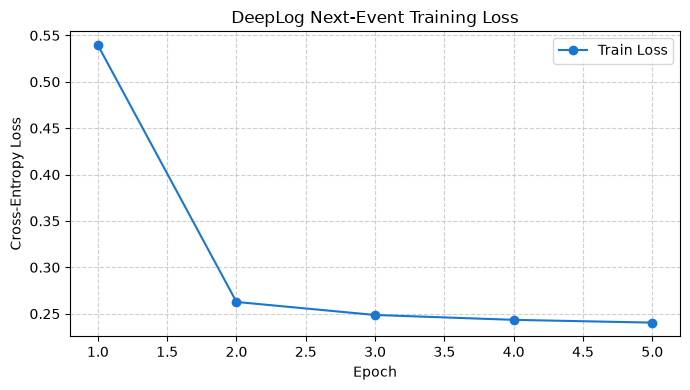

In [6]:
epoch_losses = []
start_train = time.perf_counter()

print("=== เริ่มการฝึกสอน DeepLog Next-Event Prediction ===")
for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    total_loss = 0.0
    total_samples = 0
    epoch_start = time.perf_counter()

    for batch_idx, (inputs, targets) in enumerate(train_loader, start=1):
        inputs = inputs.to(DEVICE)
        targets = targets.to(DEVICE)

        optimizer.zero_grad()
        logits = model(inputs)
        loss = criterion(logits, targets)
        loss.backward()
        optimizer.step()

        batch_size_cur = len(targets)
        total_loss += loss.item() * batch_size_cur
        total_samples += batch_size_cur

        if batch_idx % max(1, len(train_loader) // 5) == 0 or batch_idx == len(train_loader):
            print(f"  Epoch {epoch}/{NUM_EPOCHS} | Batch {batch_idx:,}/{len(train_loader):,} | Loss: {loss.item():.4f}")

    mean_loss = total_loss / max(1, total_samples)
    epoch_losses.append(mean_loss)
    epoch_time = time.perf_counter() - epoch_start
    print(f"✅ จบ Epoch {epoch}/{NUM_EPOCHS} -> Mean Loss: {mean_loss:.4f} (ใช้เวลา {epoch_time:.1f}s)\n")

total_time = time.perf_counter() - start_train
print(f"การฝึกสอนเสร็จสมบูรณ์ในเวลา {total_time:.1f} วินาที! 🚀")

# บันทึก Checkpoint โมเดล
model_save_path = CHECKPOINT_DIR / 'deeplog_next_event_hdfs.pt'
torch.save({
    'model_state_dict': model.state_dict(),
    'vocab_size': VOCAB_SIZE,
    'window_size': WINDOW_SIZE,
    'event_to_id': event_to_id,
    'id_to_event': id_to_event
}, model_save_path)
print(f"💾 บันทึก Model Checkpoint เรียบร้อยที่: {model_save_path}")

# พล็อตกราฟ Loss
plt.figure(figsize=(7, 4))
plt.plot(range(1, NUM_EPOCHS + 1), epoch_losses, marker='o', color='#1976D2', label='Train Loss')
plt.title('DeepLog Next-Event Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Cross-Entropy Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '07_deeplog_training_loss.png', dpi=150)
plt.show()


## Step 7: ระบบตรวจจับความผิดปกติระดับ Session ด้วย Top-k Candidates

### กฎการตัดสินของ DeepLog:
1. **การตรวจสอบแต่ละสเต็ป (Step-level):**
   - โมเดลทำนายการแจกแจงความน่าจะเป็นของเหตุการณ์ถัดไป
   - เลือก **Top-$k$ Candidates** ที่มีความน่าจะเป็นสูงสุด $k$ อันดับแรก
   - หากเหตุการณ์จริงที่เกิดขึ้น $e_t$ **ไม่อยู่ใน Top-$k$** $\rightarrow$ นับเป็น **จุดผิดปกติ (Abnormal Step)**
2. **การตัดสินระดับ Session (Session-level):**
   - หากพบเหตุการณ์ผิดปกติใน Session $\ge \text{error\_threshold}$ (ปกติคือ $\ge 1$) $\rightarrow$ จัดเป็น **Session ผิดปกติ (Anomaly = 1)**
   - หากทุกเหตุการณ์สอดคล้องกับ Top-$k$ ตลอดทั้งกระบวนการ $\rightarrow$ จัดเป็น **Session ปกติ (Normal = 0)**


In [7]:
@torch.no_grad()
def detect_session_anomalies(
    model: nn.Module,
    sequences: List[List[int]],
    window_size: int = WINDOW_SIZE,
    k: int = 9,
    error_threshold: int = 1,
    batch_size: int = 4096,
    device: torch.device = DEVICE
) -> np.ndarray:
    """
    ตรวจจับ Anomaly ระดับ Session ด้วย Top-k Candidates
    ประมวลผลแบบ Vectorized Batches เพื่อความรวดเร็วสูง
    """
    model.eval()

    all_windows = []
    all_targets = []
    session_indices = []

    # 1. แตก Window สำหรับทุก Session
    for s_idx, seq in enumerate(sequences):
        if len(seq) == 0:
            continue
        padded = [PAD_ID] * window_size + seq
        for i in range(len(seq)):
            all_windows.append(padded[i:i + window_size])
            all_targets.append(seq[i])
            session_indices.append(s_idx)

    if len(all_windows) == 0:
        return np.zeros(len(sequences), dtype=int)

    all_windows = torch.tensor(all_windows, dtype=torch.long)
    all_targets = torch.tensor(all_targets, dtype=torch.long)
    session_indices = np.array(session_indices, dtype=np.int32)

    # 2. ทำนาย Top-k เป็น Batches
    is_abnormal_step = np.zeros(len(all_targets), dtype=bool)

    for start in range(0, len(all_windows), batch_size):
        end = start + batch_size
        batch_win = all_windows[start:end].to(device)
        batch_tgt = all_targets[start:end].to(device)

        logits = model(batch_win)
        _, topk = torch.topk(logits, k=k, dim=-1)

        in_topk = (topk == batch_tgt.unsqueeze(1)).any(dim=-1)
        is_abnormal_step[start:end] = (~in_topk).cpu().numpy()

    # 3. รวมจำนวนจุดผิดปกติต่อแต่ละ Session ด้วย np.bincount
    session_errors = np.bincount(session_indices[is_abnormal_step], minlength=len(sequences))
    session_preds = (session_errors >= error_threshold).astype(int)

    return session_preds

print("ฟังก์ชันตรวจจับ Anomaly ด้วย Top-k พร้อมใช้งาน ✅")


ฟังก์ชันตรวจจับ Anomaly ด้วย Top-k พร้อมใช้งาน ✅


## Step 8: จูนหาค่า $k$ ที่เหมาะสมที่สุดบน Validation Set

### เหตุผล:
- ถ้า $k$ เล็กเกินไป (เช่น $k=1$ หรือ $k=2$): โมเดลเข้มงวดเกินไป จะเกิด **False Alarm** จำนวนมาก
- ถ้า $k$ ใหญ่เกินไป (เช่น $k=25$): ช้อยส์กว้างเกินไป ทำให้คนร้ายหลุดรอดได้ง่าย (**Recall ตก**)
- เราจึงต้องทดลองค่า $k \in [1, 2, 3, 5, 7, 9, 12, 15]$ บน **Validation Set** เพื่อหาจุดที่ให้ค่า **F1-Score สูงที่สุด**


=== จูนค่า k บน Validation Set (86,259 sessions) ===
k =  1 -> F1: 0.0723 | Recall: 1.0000 | Precision: 0.0375 (ใช้เวลา 13.9s)
k =  2 -> F1: 0.1790 | Recall: 0.8198 | Precision: 0.1005 (ใช้เวลา 16.1s)
k =  3 -> F1: 0.3184 | Recall: 0.7988 | Precision: 0.1988 (ใช้เวลา 16.1s)
k =  5 -> F1: 0.6712 | Recall: 0.5521 | Precision: 0.8557 (ใช้เวลา 16.0s)
k =  7 -> F1: 0.6256 | Recall: 0.4768 | Precision: 0.9094 (ใช้เวลา 16.9s)
k =  9 -> F1: 0.4629 | Recall: 0.3042 | Precision: 0.9685 (ใช้เวลา 16.6s)
k = 12 -> F1: 0.4332 | Recall: 0.2780 | Precision: 0.9804 (ใช้เวลา 16.0s)
k = 15 -> F1: 0.4311 | Recall: 0.2749 | Precision: 0.9986 (ใช้เวลา 15.9s)

🎯 ค่า k ที่ดีที่สุดบน Validation Set คือ: k = 5 (Validation F1 = 0.6712)


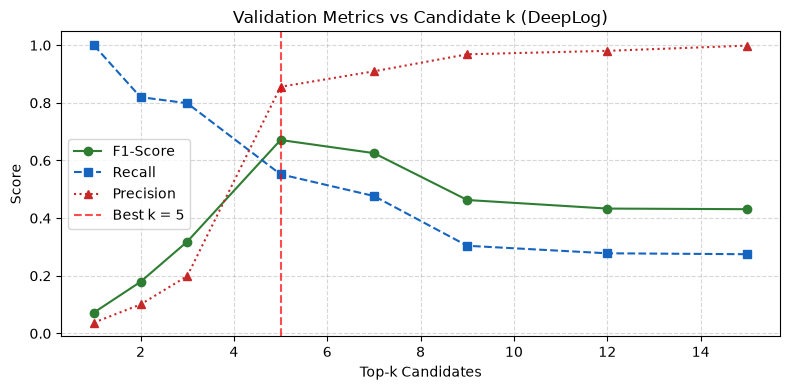

In [8]:
val_seqs = [encode_sequence(seq, event_to_id) for seq in val_df['Sequence']]
val_labels = val_df['Label'].to_numpy()

k_candidates = [1, 2, 3, 5, 7, 9, 12, 15]
val_f1_scores = []
val_recalls = []
val_precisions = []

print(f"=== จูนค่า k บน Validation Set ({len(val_df):,} sessions) ===")
for candidate_k in k_candidates:
    t0 = time.perf_counter()
    preds = detect_session_anomalies(model, val_seqs, k=candidate_k)
    f1 = f1_score(val_labels, preds, zero_division=0)
    rec = recall_score(val_labels, preds, zero_division=0)
    prec = precision_score(val_labels, preds, zero_division=0)

    val_f1_scores.append(f1)
    val_recalls.append(rec)
    val_precisions.append(prec)
    print(f"k = {candidate_k:2d} -> F1: {f1:.4f} | Recall: {rec:.4f} | Precision: {prec:.4f} (ใช้เวลา {time.perf_counter()-t0:.1f}s)")

best_idx = int(np.argmax(val_f1_scores))
best_k = k_candidates[best_idx]
print(f"\n🎯 ค่า k ที่ดีที่สุดบน Validation Set คือ: k = {best_k} (Validation F1 = {val_f1_scores[best_idx]:.4f})")

# พล็อตกราฟ F1 vs k
plt.figure(figsize=(8, 4))
plt.plot(k_candidates, val_f1_scores, marker='o', color='#2E7D32', label='F1-Score')
plt.plot(k_candidates, val_recalls, marker='s', linestyle='--', color='#1565C0', label='Recall')
plt.plot(k_candidates, val_precisions, marker='^', linestyle=':', color='#C62828', label='Precision')
plt.axvline(best_k, color='red', linestyle='--', alpha=0.7, label=f'Best k = {best_k}')
plt.title('Validation Metrics vs Candidate k (DeepLog)')
plt.xlabel('Top-k Candidates')
plt.ylabel('Score')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '08_deeplog_val_k_tuning.png', dpi=150)
plt.show()


## Step 9: ประเมินผลบน Test Set ด้วยค่า Best $k$

### ขั้นตอน:
- นำโมเดล DeepLog ไปตรวจข้อสอบปลายภาค (**Test Set** จำนวน 86,260 sessions ที่ไม่เคยเห็นมาก่อน)
- คำนวณ Confusion Matrix และ Classification Report
- บันทึกผลลัพธ์เป็น JSON สำหรับนำไปเปรียบเทียบในภาพรวม


=== ประเมินผล DeepLog บน Test Set (k = 5) ===
ประเมิน 86,260 sessions เสร็จสิ้นใน 13.09 วินาที

              precision    recall  f1-score   support

  Normal (0)     0.9871    0.9974    0.9922     83734
 Anomaly (1)     0.8677    0.5685    0.6869      2526

    accuracy                         0.9848     86260
   macro avg     0.9274    0.7829    0.8396     86260
weighted avg     0.9836    0.9848    0.9833     86260

True Negative  (ปกติ แล้วทายว่าปกติ):         83,515 เคส ✅
False Positive (ปกติ แต่เตือนผิด):            219 เคส ❌ (False Alarm)
False Negative (ผิดปกติ แต่โมเดลมองไม่เห็น):   1,090 เคส ❌ (หลุดรอด)
True Positive  (ผิดปกติ แล้วจับได้จริง):       1,436 เคส ✅



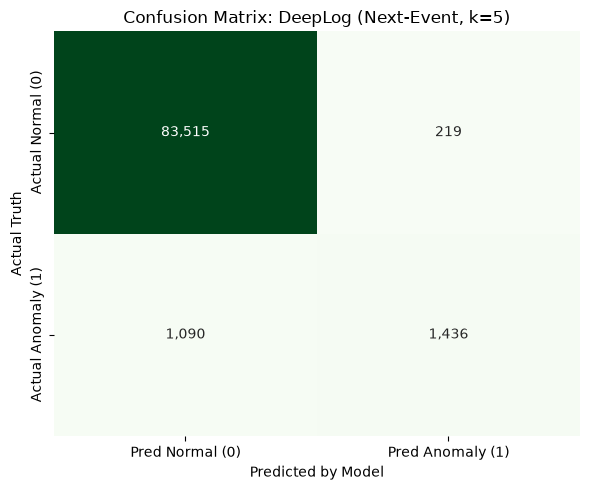

บันทึกผลการทดลองเรียบร้อยที่: ../results/metrics/deeplog_next_event_hdfs.json


In [9]:
test_seqs = [encode_sequence(seq, event_to_id) for seq in test_df['Sequence']]
test_labels = test_df['Label'].to_numpy()

print(f"=== ประเมินผล DeepLog บน Test Set (k = {best_k}) ===")
start_test = time.perf_counter()
test_predictions = detect_session_anomalies(model, test_seqs, k=best_k)
test_time = time.perf_counter() - start_test
print(f"ประเมิน {len(test_df):,} sessions เสร็จสิ้นใน {test_time:.2f} วินาที\n")

print(classification_report(test_labels, test_predictions, target_names=['Normal (0)', 'Anomaly (1)'], digits=4))

# คำนวณ Confusion Matrix
cm = confusion_matrix(test_labels, test_predictions)
tn, fp, fn, tp = cm.ravel()

print(f"True Negative  (ปกติ แล้วทายว่าปกติ):         {tn:,} เคส ✅")
print(f"False Positive (ปกติ แต่เตือนผิด):            {fp:,} เคส ❌ (False Alarm)")
print(f"False Negative (ผิดปกติ แต่โมเดลมองไม่เห็น):   {fn:,} เคส ❌ (หลุดรอด)")
print(f"True Positive  (ผิดปกติ แล้วจับได้จริง):       {tp:,} เคส ✅\n")

# วาดกราฟ Confusion Matrix Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Greens', cbar=False,
            xticklabels=['Pred Normal (0)', 'Pred Anomaly (1)'],
            yticklabels=['Actual Normal (0)', 'Actual Anomaly (1)'])
plt.title(f'Confusion Matrix: DeepLog (Next-Event, k={best_k})')
plt.ylabel('Actual Truth')
plt.xlabel('Predicted by Model')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '08_confusion_matrix_deeplog.png', dpi=150)
plt.show()

# บันทึก Metric JSON
test_f1 = float(f1_score(test_labels, test_predictions, zero_division=0))
test_prec = float(precision_score(test_labels, test_predictions, zero_division=0))
test_rec = float(recall_score(test_labels, test_predictions, zero_division=0))

deeplog_metrics = {
    'model': 'DeepLog_NextEvent',
    'dataset': 'HDFS',
    'training_paradigm': 'Unsupervised/Semi-supervised (Normal sessions only)',
    'window_size': WINDOW_SIZE,
    'best_k': best_k,
    'f1_score': round(test_f1, 4),
    'precision': round(test_prec, 4),
    'recall': round(test_rec, 4),
    'confusion_matrix': cm.tolist(),
    'hyperparameters': {
        'embedding_dim': EMBEDDING_DIM,
        'hidden_dim': HIDDEN_DIM,
        'num_layers': NUM_LAYERS,
        'dropout': DROPOUT,
        'learning_rate': LEARNING_RATE,
        'batch_size': BATCH_SIZE,
        'epochs': NUM_EPOCHS,
        'train_sessions_used': len(train_for_model)
    },
    'timestamp': time.strftime('%Y-%m-%d %H:%M:%S')
}

metric_file = METRIC_DIR / 'deeplog_next_event_hdfs.json'
with open(metric_file, 'w', encoding='utf-8') as f:
    json.dump(deeplog_metrics, f, indent=4, ensure_ascii=False)

print(f"บันทึกผลการทดลองเรียบร้อยที่: {metric_file}")


## Step 10: สรุปเปรียบเทียบโมเดลทั้งหมดที่พัฒนาในโครงการ (Week 1 - Week 4)

### ตารางเปรียบเทียบประสิทธิภาพ:
รวบรวมผลลัพธ์จากทั้ง 4 โมเดลที่บันทึกไว้ใน `results/metrics/`:
1. **Logistic Regression** (Baseline - Supervised Event Count)
2. **Isolation Forest** (Baseline - Unsupervised Event Count)
3. **Supervised Session LSTM** (Week 4 - Supervised Sequence Classification)
4. **DeepLog Next-Event Prediction** (Week 4b - Unsupervised Sequence Modeling)


In [10]:
comparison_rows = []

metric_files = {
    'Logistic Regression': METRIC_DIR / 'logistic_regression_hdfs.json',
    'Isolation Forest': METRIC_DIR / 'isolation_forest_hdfs.json',
    'Supervised Session LSTM': METRIC_DIR / 'lstm_deeplog_hdfs.json',
    'DeepLog (Next-Event)': METRIC_DIR / 'deeplog_next_event_hdfs.json'
}

for name, file_path in metric_files.items():
    if file_path.is_file():
        with open(file_path, 'r', encoding='utf-8') as f:
            data = json.load(f)
            comparison_rows.append({
                'Model': name,
                'Paradigm': 'Supervised' if 'supervised' in name.lower() or name == 'Logistic Regression' else 'Unsupervised',
                'Precision': f"{data.get('precision', 0.0) * 100:.2f}%",
                'Recall': f"{data.get('recall', 0.0) * 100:.2f}%",
                'F1-Score': f"{data.get('f1_score', 0.0) * 100:.2f}%",
                'PR-AUC': f"{data.get('pr_auc', 0.0) * 100:.2f}%" if 'pr_auc' in data else 'N/A'
            })

if comparison_rows:
    comp_df = pd.DataFrame(comparison_rows).set_index('Model')
    print("=== สรุปผลการเปรียบเทียบทุกโมเดลบน HDFS Test Set ===")
    display(comp_df)
else:
    print("ยังไม่พบไฟล์ metrics ครบทุกโมเดล")


=== สรุปผลการเปรียบเทียบทุกโมเดลบน HDFS Test Set ===


,Paradigm,Precision,Recall,F1-Score,PR-AUC
Model,,,,,
Logistic Regression,Supervised,96.12%,100.00%,98.02%,97.53%
Isolation Forest,Unsupervised,64.74%,62.67%,63.69%,73.36%
Supervised Session LSTM,Supervised,97.64%,99.80%,98.71%,99.96%
DeepLog (Next-Event),Unsupervised,86.77%,56.85%,68.69%,N/A
